# Inference

x:\language\python\Lib\site-packages\keras\src\saving\saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 16 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Created mapping for 905 image IDs to filenames
Testing food detection on image: dish_44_IMG_6615_jpeg.rf.3becfc862f397e2686c22a98e080a3a7.jpg
Predicted categories: [('hamburger', 0.5493684)]


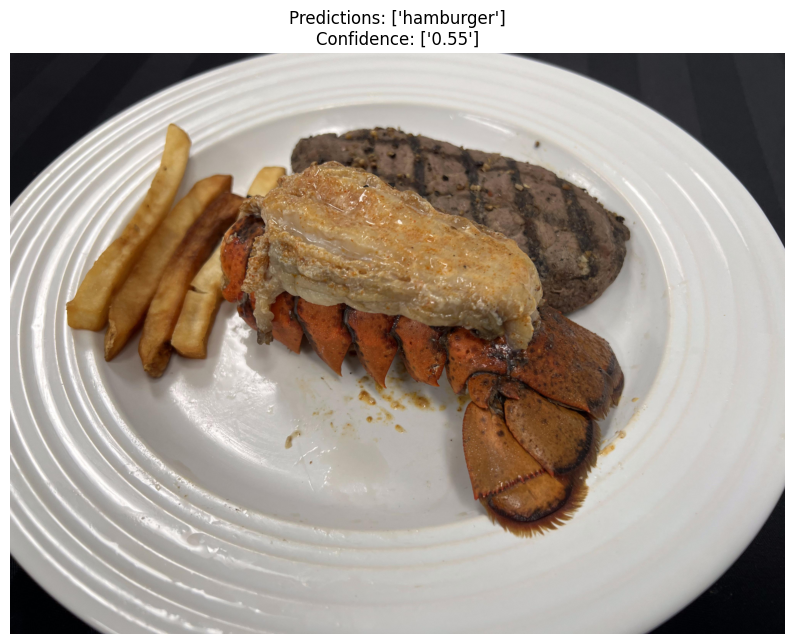

In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import cv2
import pandas as pd
import random
from sklearn.preprocessing import LabelEncoder

# Function to predict food category from an image
def predict_food_category(image_path, model, label_encoder):
    # Load and preprocess the image
    image = cv2.imread(image_path)
    if image is None:
        return "Error: Could not load image"
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    # Find food regions using COCO annotations or detect with simple method
    # For demonstration, we'll use a simplified approach
    regions = extract_regions(image)
    
    if not regions:
        # If no regions found, use whole image
        regions = [cv2.resize(image, (IMG_SIZE, IMG_SIZE)) / 255.0]
    
    # Make predictions for each region
    predictions = []
    for region in regions:
        # Ensure region is in the right format for prediction
        region_processed = np.expand_dims(region, axis=0)
        
        # Predict
        pred = model.predict(region_processed, verbose=0)
        class_idx = np.argmax(pred, axis=1)[0]
        confidence = np.max(pred)
        
        # Get the category name
        try:
            category_id = label_encoder.classes_[class_idx]
            category_name = next((cat['name'] for cat in category if cat['id'] == category_id), "Unknown")
            predictions.append((category_name, confidence))
        except:
            predictions.append(("Unknown", confidence))
    
    return predictions

# Function to extract regions from an image (simplified)
def extract_regions(image):
    regions = []
    
    # For now, just return the whole image resized
    resized_img = cv2.resize(image, (IMG_SIZE, IMG_SIZE)) / 255.0
    regions.append(resized_img)
    
    return regions

# Define constants
IMG_SIZE = 224  # Input size for MobileNetV2
BATCH_SIZE = 64
EPOCHS = 15

# Load the saved model
model_path = "224_15_Epoch_raw_new.keras"
food_detection_model = tf.keras.models.load_model(model_path)

# Setting paths
base_path = 'nutritionverse-data'
images_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images')
coco_json_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images/_annotations.coco.json')
splits_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/updated-manual-dataset-splits.csv')

# Load COCO format image metadata
with open(coco_json_path, 'r') as f:
    coco_data = json.load(f)

# Optionally extract image information from COCO format
coco_images = pd.DataFrame(coco_data['images'])

# Create a mapping from image_id to file_name
image_id_to_filename = {img['id']: img['file_name'] for img in coco_data['images']}
print(f"Created mapping for {len(image_id_to_filename)} image IDs to filenames")


category = coco_data['categories']
# Extract only the 'id' values from the categories
category_ids = [cat['id'] for cat in category]

# Initialize and fit the LabelEncoder
label_encoder = LabelEncoder()
label_encoder.fit(category_ids)


# Test the detection on a sample image
sample_image_id = random.choice(list(image_id_to_filename.keys()))
sample_filename = image_id_to_filename[sample_image_id]
sample_image_path = os.path.join(images_path, sample_filename)

print(f"Testing food detection on image: {sample_filename}")

# Predict food categories
predictions = predict_food_category(sample_image_path, food_detection_model, label_encoder)
print(f"Predicted categories: {predictions}")

# Display the image with predictions
plt.figure(figsize=(10, 8))
img = plt.imread(sample_image_path)
plt.imshow(img)
plt.title(f"Predictions: {[p[0] for p in predictions]}\nConfidence: {[f'{p[1]:.2f}' for p in predictions]}")
plt.axis('off')
plt.show()

